In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

In [117]:
dataset = "atac/new"
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")

In [118]:
# ---------- I/O ----------
adata = sc.read_h5ad(os.path.join(res_path, "small_atac_gene_activity.h5ad"))

# Seurat code used 'counts = ...$counts'. In AnnData this is usually .layers["counts"].
# Fall back to .X if the layer is missing.
if "counts" in adata.layers:
    adata.X = adata.layers["counts"].copy()

# Match Seurat’s col/row naming:
#   colnames(counts) = rownames(data0@colData)  -> adata.obs_names already
#   rownames(counts) = names(data0@rowRanges)   -> adata.var_names already

In [119]:
# ---------- Build metadata ----------
# meta.data <- data.frame(method = batchname, cell_type = final_cell_label)
# Make sure these columns exist in adata.obs; rename here if needed.
obs = adata.obs
required_cols = ["batchname", "final_cell_label"]
missing = [c for c in required_cols if c not in obs.columns]
if missing:
    raise KeyError(f"Missing columns in adata.obs: {missing}")

adata.obs["method"] = obs["batchname"].astype(str)
adata.obs["cell_type"] = obs["final_cell_label"].astype("category")

In [120]:
# ---------- Filters (CreateSeuratObject: min.cells=3, min.features=10) ----------
# min.features=10 -> keep cells with >=10 detected genes
sc.pp.filter_cells(adata, min_genes=10)
# min.cells=3 -> keep genes detected in >=3 cells
sc.pp.filter_genes(adata, min_cells=3)

In [121]:
# ---------- Keep the two methods and relabel as data1 / data2 ----------
# X1 <- "10x Genomics"; X2 <- "Fang et al."
keep = ["10x Genomics", "Fang et al."]
adata = adata[adata.obs["method"].isin(keep)].copy()
adata.obs["method"] = adata.obs["method"].map({
    "10x Genomics": "data1",
    "Fang et al.": "data2"
}).astype("category")

In [122]:
# Keep raw counts before any normalization
if "counts" not in adata.layers:
    adata.layers["counts"] = adata.X.copy()   # X must still be raw counts here

# HVGs from raw counts (across batches)
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat_v3",
    n_top_genes=1000,
    batch_key="method",
    layer="counts"          # <<< key change
)

# Now do the typical normalize + log for downstream analyses
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Subset to HVGs (same feature set as Seurat's SelectIntegrationFeatures)
adata_hv = adata[:, adata.var["highly_variable"]].copy()
features = adata_hv.var_names.to_list()

In [123]:
# ---------- Split to X1 / X2 with identical gene order ----------
X1 = adata_hv[adata_hv.obs["method"] == "data1"].X
X2 = adata_hv[adata_hv.obs["method"] == "data2"].X

# Dense arrays (Seurat used as.matrix(...))
X1 = X1.toarray() if hasattr(X1, "toarray") else np.asarray(X1)
X2 = X2.toarray() if hasattr(X2, "toarray") else np.asarray(X2)

In [124]:
unique_cell_types, y  = np.unique(adata_hv.obs["cell_type"], return_inverse=True)
y1, y2 = adata_hv.obs["method"] == "data1", adata_hv.obs["method"] == "data2"

In [134]:
# ---------- (Optional) Save like in your previous workflow ----------
outdir = res_path  # assume res_path is already defined

np.save(os.path.join(outdir, "data1.npy"), X1)                    # corresponds to "10x Genomics"
np.save(os.path.join(outdir, "data2.npy"), X2)                    # corresponds to "Fang et al."
np.save(os.path.join(outdir, "dataset_names.npy"), np.array(["10X Genomics", "Fang et al."]))

np.save(os.path.join(outdir, "labels1.npy"), y1)
np.save(os.path.join(outdir, "labels2.npy"), y2)
np.save(os.path.join(outdir, "cell_type_names.npy"), unique_cell_types)


pd.Series(features, name="gene").to_csv(os.path.join(outdir, "features.txt"), index=False)
adata_hv.obs.to_csv(os.path.join(outdir, "cells_metadata.csv"))   # includes cell_type and method
adata_hv.write(os.path.join(outdir, "combined_1000genes.h5ad"))   # convenient all-in-one AnnData file

In [126]:
X1.shape, X2.shape

((3618, 1000), (3750, 1000))

In [127]:

obs


,batchname,batchname_all,final_cell_label,method,cell_type,n_genes
AAACGAAAGTAATCAG-1-0-0,10x Genomics,10x Genomics,Excitatory Neurons,10x Genomics,Excitatory Neurons,1974
AAACGAACACGCTGTG-1-0-0,10x Genomics,10x Genomics,Excitatory Neurons,10x Genomics,Excitatory Neurons,874
AAACGAATCCTGGGAC-1-0-0,10x Genomics,10x Genomics,Excitatory Neurons,10x Genomics,Excitatory Neurons,1268
AAACGAATCGGGAAAC-1-0-0,10x Genomics,10x Genomics,Inhibitory Neurons,10x Genomics,Inhibitory Neurons,1213
AAACTCGAGAAAGCAG-1-0-0,10x Genomics,10x Genomics,Excitatory Neurons,10x Genomics,Excitatory Neurons,1551
...,...,...,...,...,...,...
TCTCGCGCTTGCGAGCATTCAAGATAGTCAGGACGT-1,Cusanovich et al.,Cusanovich et al. - WholeBrainA_62216,Cerebellar Granule Cells,Cusanovich et al.,Cerebellar Granule Cells,557
TCTCGCGCTTGCTTAGATAGGCGAGAGCGGCTCTGA-1,Cusanovich et al.,Cusanovich et al. - WholeBrainA_62216,Microglia,Cusanovich et al.,Microglia,131
TCTCGCGCTTGCTTAGATCAGAGAGGTCATAGAGGC-1,Cusanovich et al.,Cusanovich et al. - WholeBrainA_62216,Excitatory Neurons,Cusanovich et al.,Excitatory Neurons,370
TCTCGCGCTTGCTTAGATCAGCCGGCTTGGCTCTGA-1,Cusanovich et al.,Cusanovich et al. - WholeBrainA_62216,Inhibitory Neurons,Cusanovich et al.,Inhibitory Neurons,305


In [128]:
from openTSNE import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [129]:
cmap = plt.get_cmap("tab10")

color1 = np.array([cmap(i) for i in y[adata_hv.obs["method"] == "data1"]])
color2 = np.array([cmap(i) for i in y[adata_hv.obs["method"] == "data2"]])
colorj = np.array([cmap(i) for i in y])

In [130]:
pca1_50 = PCA(n_components=50).fit_transform(X1)
pca2_50 = PCA(n_components=50).fit_transform(X2)
pcaj_50 = PCA(n_components=50).fit_transform(np.concatenate((X1, X2)))

Text(0.5, 0.98, 'PCA2 results of sc dataset')

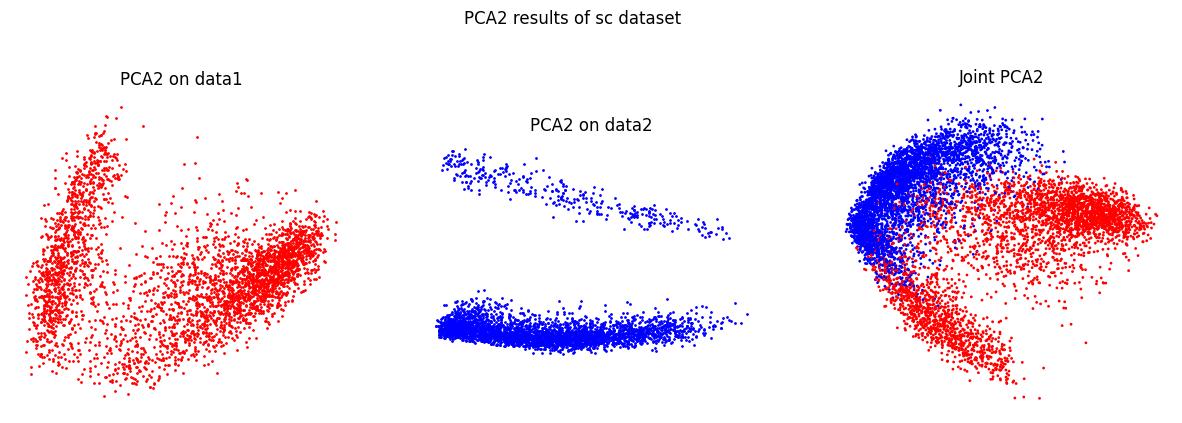

In [131]:


fig, ax = plt.subplots(1,3, figsize=(15,5))
ax[0].scatter(*pca1_50[:, :2].T, s=1, c="r")
ax[0].set_title("PCA2 on data1")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("PCA2 on data2")
ax[1].scatter(*pca2_50[:, :2].T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("Joint PCA2")

order = np.random.permutation(pcaj_50.shape[0])
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
ax[2].scatter(*pcaj_50[order, :2].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")


fig.suptitle("PCA2 results of sc dataset")

#fig.savefig(os.path.join(fig_path, f"{dataset}_pca2.png"), dpi=300)

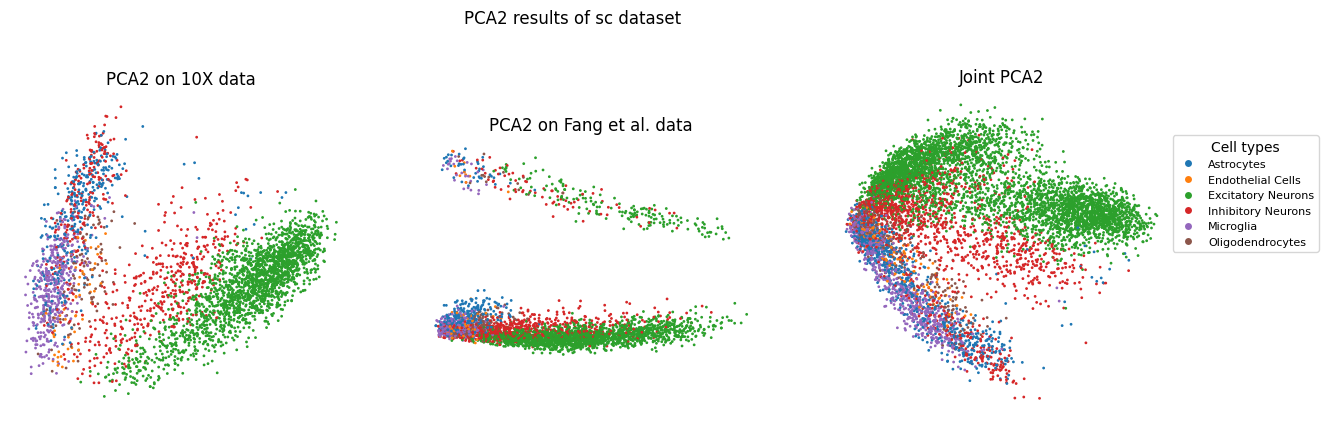

In [54]:
fig, ax = plt.subplots(1,3, figsize=(15,5))
ax[0].scatter(*pca1_50[:, :2].T, s=1, c=color1)
ax[0].set_title("PCA2 on 10X data")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("PCA2 on Fang et al. data")
ax[1].scatter(*pca2_50[:, :2].T, s=1, c=color2)
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("Joint PCA2")

order = np.random.permutation(pcaj_50.shape[0])
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
ax[2].scatter(*pcaj_50[order, :2].T, s=1, c=colorj[order])
ax[2].set_aspect("equal")
ax[2].axis("off")

handles = [
    mlines.Line2D(
        [], [], linestyle="none", marker="o",
        markersize=5, markerfacecolor=cmap(i ),
        markeredgecolor="none", label=str(lbl)
    )
    for i, lbl in enumerate(unique_cell_types)
]

ax[2].legend(handles=handles, title="Cell types", loc=(1.0, 0.5), fontsize=8)


fig.suptitle("PCA2 results of sc dataset")

fig.savefig(os.path.join(fig_path, f"{dataset}_by_type_pca2.png"), dpi=300)

In [132]:
tsne1 = TSNE(verbose=True).fit(pca1_50)
tsne2 = TSNE(verbose=True).fit(pca2_50)
tsnej = TSNE(verbose=True).fit(pcaj_50)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 1.37 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.12 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.01 seconds
===> Running optimization with exaggeration=12.00, lr=301.50 for 250 iterations...
Iteration   50, KL divergence 3.9196, 50 iterations in 4.4686 sec
Iteration  100, KL divergence 3.9831, 50 iterations in 4.1478 sec
Iteration  150, KL divergence 3.9825, 50 iterations in 3.9957 sec
Iteration  200, KL divergence 3.9824, 50 iterations in 3.9431 sec
Iteration  250, KL divergence 3.9824, 50 iterations in 3.9589 sec
   --> Time elapsed: 20.52 seconds
===> Running optimization with exaggeration=1.00, lr=3618.00 for 500 ite

Text(0.5, 0.98, 'tSNEs on atac dataset')

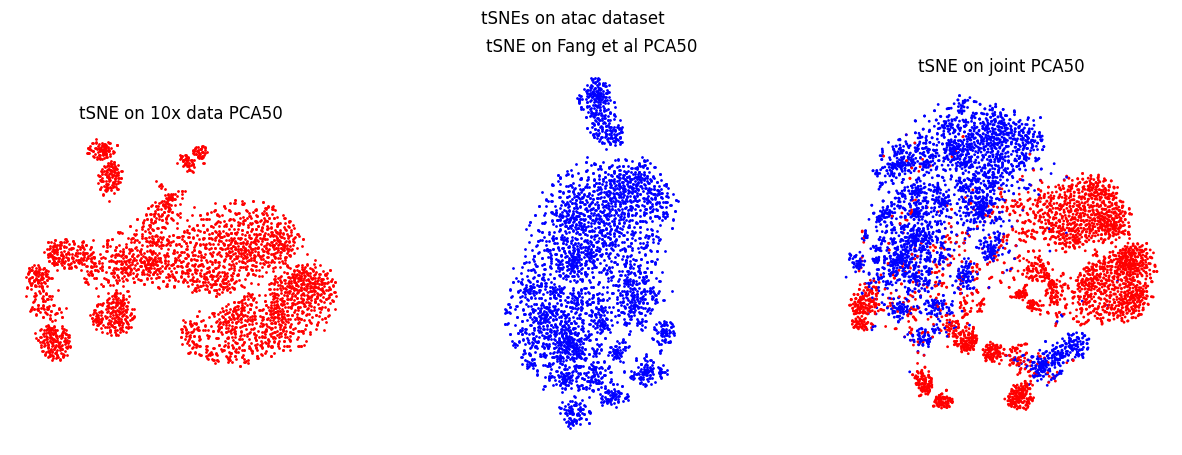

In [133]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

ax[0].scatter(*tsne1.T, s=1, c="r")
ax[0].set_title("tSNE on 10x data PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on Fang et al PCA50")
ax[1].scatter(*tsne2.T, s=1, c="b")
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=np.array(colors)[order])
ax[2].set_aspect("equal")
ax[2].axis("off")
fig.suptitle("tSNEs on atac dataset")

#fig.savefig(os.path.join(fig_path, f"{dataset}_tsne.png"), dpi=300)

In [36]:
import matplotlib.lines as mlines

/tmp/ipykernel_3420458/1705611417.py:18: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax[2].scatter(*tsnej[order].T, s=1, c=[cmap(i) for i in y[order]], cmap="tab10")


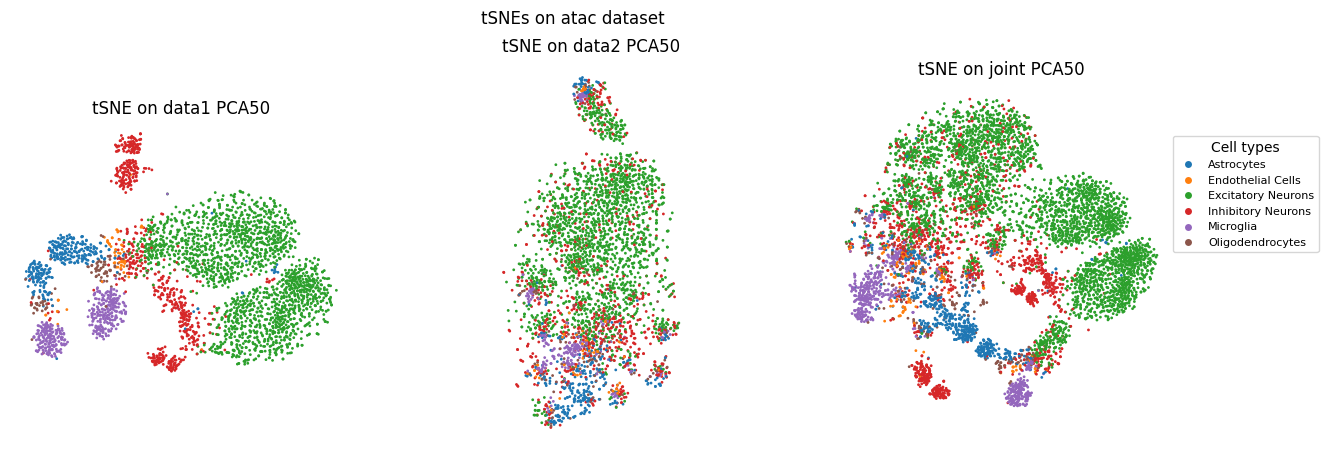

In [42]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

cmap = plt.get_cmap("tab10")

ax[0].scatter(*tsne1.T, s=1, c=[cmap(i) for i in y[adata_hv.obs["method"] == "data1"]])
ax[0].set_title("tSNE on 10x data PCA50")
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].set_title("tSNE on Fang et al PCA50")
ax[1].scatter(*tsne2.T, s=1, c=[cmap(i) for i in y[adata_hv.obs["method"] == "data2"]])
ax[1].set_aspect("equal")
ax[1].axis("off")

ax[2].set_title("tSNE on joint PCA50")
colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]
order = np.random.permutation(len(colors))
ax[2].scatter(*tsnej[order].T, s=1, c=[cmap(i) for i in y[order]], cmap="tab10")
ax[2].set_aspect("equal")
ax[2].axis("off")
fig.suptitle("tSNEs on atac dataset")

handles = [
    mlines.Line2D(
        [], [], linestyle="none", marker="o",
        markersize=5, markerfacecolor=cmap(i ),
        markeredgecolor="none", label=str(lbl)
    )
    for i, lbl in enumerate(unique_cell_types)
]

ax[2].legend(handles=handles, title="Cell types", loc=(1.0, 0.5), fontsize=8)

fig.savefig(os.path.join(fig_path, f"{dataset}_by_type_tsne.png"), dpi=300)

In [ ]:
from ne_aligned_utils.utils import compute_ot_plan, sparsify_plan, get_bipartite_graph
from openTSNE.affinity import Affinities


In [ ]:
eps_times = 1
tol = 1e-12
maxIter = int(1e4)
sparsify = "topk"

In [ ]:
P = compute_ot_plan(X1, X2, eps_times=eps_times, tol=tol, maxIter=maxIter)

In [ ]:
P_sparse = sparsify_plan(P, mode=sparsify, k=15)

In [ ]:
graph = get_bipartite_graph(P_sparse)
graph.sum_duplicates()
graph /= graph.sum()

In [ ]:
init = pcaj_50[:, :2]
init /= init[:, 0].std() * 10000
n_epochs = 750
embd_dim = 2
seed = 0

# compute embedding
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=seed,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)
affinities = Affinities()
affinities.P = graph.tocsr()

embd = embedder.fit(affinities=affinities, initialization=init)

In [99]:
eps_times = 1
tol = 1e-12
maxIter = int(1e4)
embd_dim = 2

n0 = pca1_50.shape[0]
n1 = pca2_50.shape[0]

n_epochs = 200
n_early_epochs = n_epochs // 3
n_late_epochs = n_epochs - n_early_epochs



In [100]:
from ne_aligned_utils.utils import compute_ot_plan, sparsify_plan, get_bipartite_graph
from openTSNE.affinity import Affinities

from openTSNE import TSNE

In [101]:
P = compute_ot_plan(pca1_50, pca2_50, eps_times=eps_times, tol=tol, maxIter=maxIter)

U, S, V = np.linalg.svd(P, full_matrices=False)


In [102]:
t = 0
eot0_embd = np.concatenate([U * S ** t * np.sqrt(n0),
                            V.T * S ** t * np.sqrt(n1)], axis=0)

In [103]:
#init = np.random.randn(n0 + n1, 2) * 0.0001
init = pcaj_50[:, :2] * 0.0001
#init = eot0_embd[:, 1:3] * 0.0001

In [104]:
P_diag = eot0_embd @ np.diag(S) @ eot0_embd.T / np.sqrt(n0 * n1)


In [105]:
import scipy.sparse as sp

In [106]:
P_diag[P_diag < 0] = 0
np.fill_diagonal(P_diag, 0)



In [107]:
graph = sp.csr_matrix(P_diag/ P_diag.sum())

embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph.tocsr()

embd_aligned_tsne_diag = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=614.00 for 66 iterations...
Iteration   50, KL divergence -0.2296, 50 iterations in 29.4352 sec
   --> Time elapsed: 37.47 seconds
===> Running optimization with exaggeration=1.00, lr=7368.00 for 134 iterations...
Iteration   50, KL divergence 0.0127, 50 iterations in 29.4680 sec
Iteration  100, KL divergence 0.0125, 50 iterations in 28.8708 sec
   --> Time elapsed: 77.50 seconds


In [108]:
k = 15

P_diag_sparse = np.zeros_like(P_diag)

P_diag_sparse[:n0, :n0][np.arange(n0,dtype=int)[:, None], P_diag[:n0, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[:n0, n0:][np.arange(n0,dtype=int)[:, None], P_diag[:n0, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1

P_diag_sparse[n0:, :n0][np.arange(n1,dtype=int)[:, None], P_diag[n0:, :n0].argsort(axis=1)[:, -k:]] = 1
P_diag_sparse[n0:, n0:][np.arange(n1,dtype=int)[:, None], P_diag[n0:, n0:].argsort(axis=1)[:, -int(k*n1/n0):]] = 1

In [109]:
graph_sparse = sp.csr_matrix(P_diag_sparse / P_diag_sparse.sum())
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph_sparse.tocsr()

embd_aligned_tsne_diag_sparse = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=614.00 for 66 iterations...
Iteration   50, KL divergence 5.0875, 50 iterations in 11.6158 sec
   --> Time elapsed: 15.80 seconds
===> Running optimization with exaggeration=1.00, lr=7368.00 for 134 iterations...
Iteration   50, KL divergence 4.6324, 50 iterations in 10.3900 sec
Iteration  100, KL divergence 4.7663, 50 iterations in 10.5620 sec
   --> Time elapsed: 28.44 seconds


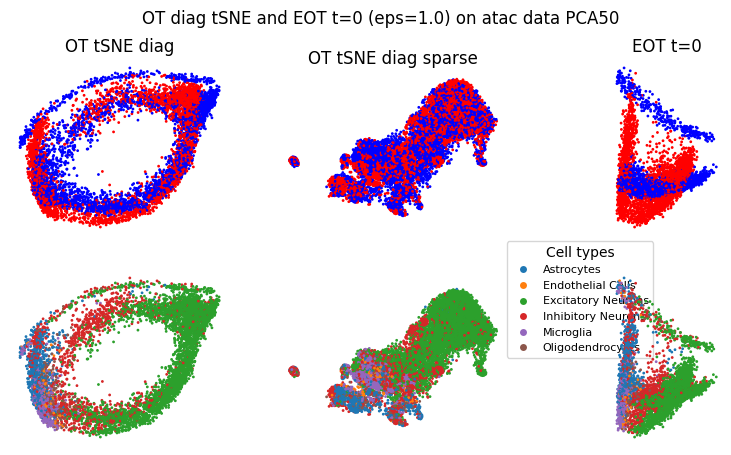

In [115]:
fig, ax = plt.subplots(2,3, figsize=(10,5))

ax[0, 0].set_title("OT tSNE diag")
colors = np.array(["r"] * X1.shape[0] + ["b"] * X2.shape[0])
order = np.random.permutation(len(colors))
ax[0, 0].scatter(*embd_aligned_tsne_diag[order].T, s=1, c=colors[order])
ax[0, 0].set_aspect("equal")
ax[0, 0].axis("off")

ax[0, 1].set_title("OT tSNE diag sparse")
ax[0, 1].scatter(*embd_aligned_tsne_diag_sparse[order].T, s=1, c=colors[order])
ax[0, 1].set_aspect("equal")
ax[0, 1].axis("off")


ax[0, 2].set_title("EOT t=0")
ax[0, 2].scatter(*eot0_embd[order, 1:3].T, s=1, c=colors[order])
ax[0, 2].set_aspect("equal")
ax[0, 2].axis("off")

ax[1, 0 ].scatter(*embd_aligned_tsne_diag[order].T, s=1, c=colorj[order])
ax[1, 0 ].set_aspect("equal")
ax[1, 0 ].axis("off")

ax[1, 1].scatter(*embd_aligned_tsne_diag_sparse[order].T, s=1, c=colorj[order])
ax[1, 1].set_aspect("equal")
ax[1, 1].axis("off")

ax[1, 2].scatter(*eot0_embd[order, 1:3].T, s=1, c=colorj[order])
ax[1, 2].set_aspect("equal")
ax[1, 2].axis("off")

fig.suptitle(f"OT diag tSNE and EOT t=0 (eps={1/eps_times}) on atac data PCA50")

handles = [
    mlines.Line2D(
        [], [], linestyle="none", marker="o",
        markersize=5, markerfacecolor=cmap(i ),
        markeredgecolor="none", label=str(lbl)
    )
    for i, lbl in enumerate(unique_cell_types)
]

ax[1,1].legend(handles=handles, title="Cell types", loc=(1.0, 0.5), fontsize=8)

fig.savefig(os.path.join(fig_path, f"{dataset}_fig_ot_diag_tsne_eps_{eps_times}.png"), dpi=300)

In [112]:
sparsify = "weighted_topk"
P_sparse = sparsify_plan(P, mode=sparsify, k=15)

graph = get_bipartite_graph(P_sparse)


graph.sum_duplicates()
graph /= graph.sum()

In [113]:
embedder = TSNE(n_components=embd_dim,
                verbose=True,
                random_state=0,
                early_exaggeration_iter=n_early_epochs,
                n_iter=n_late_epochs)

affinities = Affinities()
affinities.P = graph.tocsr()

embd_aligned_tsne_no_diag = embedder.fit(affinities=affinities, initialization=init)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=614.00 for 66 iterations...
Iteration   50, KL divergence 5.7522, 50 iterations in 18.7217 sec
   --> Time elapsed: 23.93 seconds
===> Running optimization with exaggeration=1.00, lr=7368.00 for 134 iterations...
Iteration   50, KL divergence 4.1396, 50 iterations in 11.5096 sec
Iteration  100, KL divergence 4.0887, 50 iterations in 11.0400 sec
   --> Time elapsed: 30.08 seconds


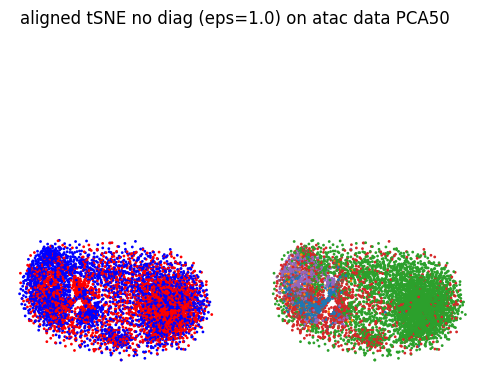

In [114]:
fig, ax = plt.subplots(1, 2, figsize=(6, 6))

colors = ["r"] * X1.shape[0] + ["b"] * X2.shape[0]

order = np.random.permutation(len(colors))
ax[0].scatter(*embd_aligned_tsne_no_diag[order].T, s=1, c=np.array(colors)[order])
ax[0].set_aspect("equal")
ax[0].axis("off")

ax[1].scatter(*embd_aligned_tsne_no_diag[order].T, s=1, c=colorj[order])
ax[1].set_aspect("equal")
ax[1].axis("off")
fig.suptitle(f"aligned tSNE no diag (eps={1/eps_times}) on atac data PCA50")
fig.savefig(os.path.join(fig_path, f"{dataset}_fig_aligned_tsne_no_diag_eps_{eps_times}.png"), dpi=300)